# Branching Fraction Plots

In [1]:
from lights.models import Model
from lights.branching_fractions import K, KS
from lights.constants import mB, mK, mKs
from lights.plotting import setup_style
from lights.paths import PLOTS_DIR

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

SAVE_DIR = PLOTS_DIR / "branching_fractions"
setup_style()

In [2]:
def plot_spectra(models, row, ylim, title, file, ncol = 1):
    """Normalised q^2 spectra 1/B dB/dq^2 of each labelled model, for the K (row = K) or K* (row = KS) mode."""
    qsq_max = (mB - (mK if row == K else mKs))**2
    qsq_vals = np.linspace(1e-3, qsq_max, 200)

    fig, axes = plt.subplots(nrows = 1, ncols = 1)
    for label, model in models.items():
        BR = quad(lambda qsq: model.dBdqsq(qsq)[row], 0.0001, qsq_max)[0]
        axes.plot(qsq_vals, model.dBdqsq(qsq_vals)[row] / BR, label = label)

    axes.set_xlim(0, qsq_max)
    axes.set_ylim(*ylim)
    plt.ticklabel_format(style = 'sci', axis = 'y', scilimits = (0, 0))
    axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$')
    axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$')
    axes.legend(loc = 'upper left', fontsize = 15, frameon = False, ncol = ncol)
    plt.title(title, fontsize = 15)
    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')

## $B\to K E_{\mathrm{miss}}$

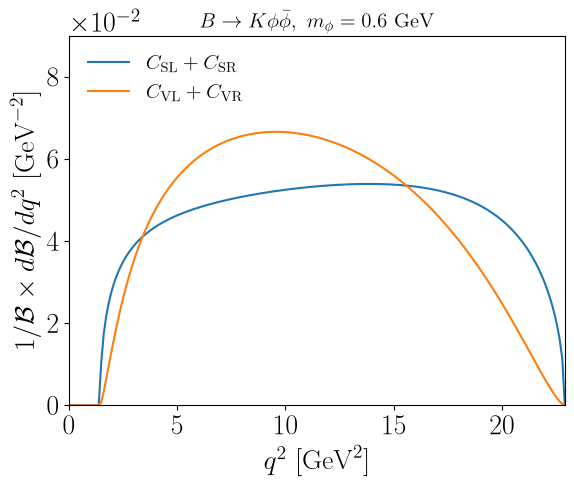

In [3]:
m = 0.6   # mass of the invisible particles [GeV]

plot_spectra({
    r'$C_{\rm SL} + C_{\rm SR}$': Model("phiphi", m, CSL = 1., CSR = 1.),
    r'$C_{\rm VL} + C_{\rm VR}$': Model("phiphi", m, CVL = 1., CVR = 1.),
}, K, ylim = (0, 0.09), title = r'$B\to K \phi\bar{\phi}, ~ m_\phi = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoK_3body_scalar.pdf")

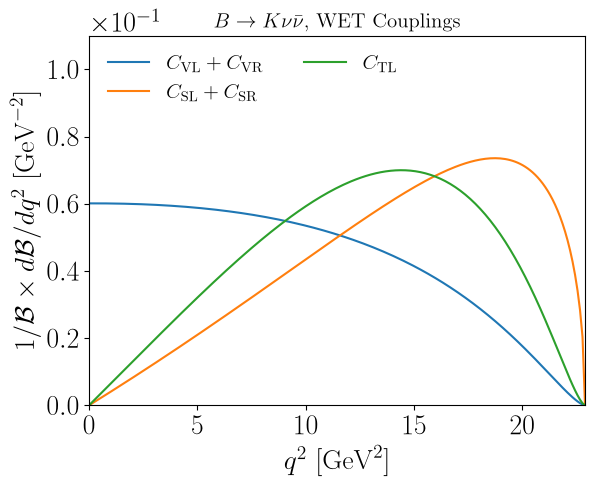

In [4]:
plot_spectra({
    r'$C_{\rm VL} + C_{\rm VR}$': Model("nunu", m, CVL = 1., CVR = 1.),
    r'$C_{\rm SL} + C_{\rm SR}$': Model("nunu", m, CSL = 1., CSR = 1.),
    r'$C_{\rm TL}$': Model("nunu", m, CTL = 1.),
}, K, ylim = (0, 0.11), title = r'$B\to K \nu\bar{\nu}$, WET Couplings',
   file = "BtoK_3body_WET.pdf", ncol = 2)

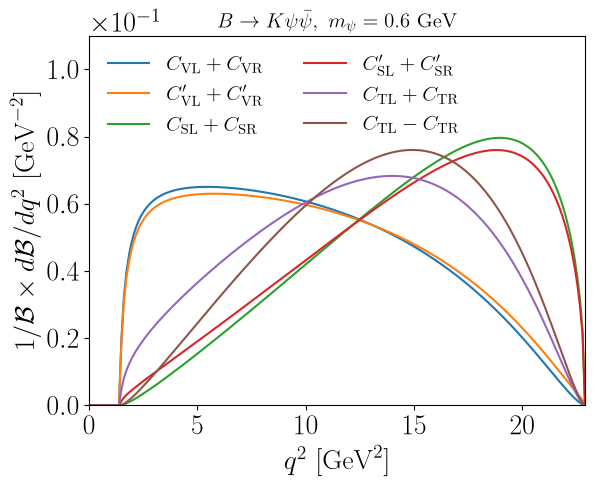

In [5]:
plot_spectra({
    r'$C_{\rm VL} + C_{\rm VR}$': Model("psipsi", m, CVL = 1., CVR = 1.),
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$': Model("psipsi", m, CVLp = 1., CVRp = 1.),
    r'$C_{\rm SL} + C_{\rm SR}$': Model("psipsi", m, CSL = 1., CSR = 1.),
    r'$C_{\rm SL}^{\prime} + C_{\rm SR}^{\prime}$': Model("psipsi", m, CSLp = 1., CSRp = 1.),
    r'$C_{\rm TL} + C_{\rm TR}$': Model("psipsi", m, CTL = 1., CTR = 1.),
    r'$C_{\rm TL} - C_{\rm TR}$': Model("psipsi", m, CTL = 1., CTR = -1.),
}, K, ylim = (0, 0.11), title = r'$B\to K \psi\bar{\psi}, ~m_\psi = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoK_3body_fermion.pdf", ncol = 2)

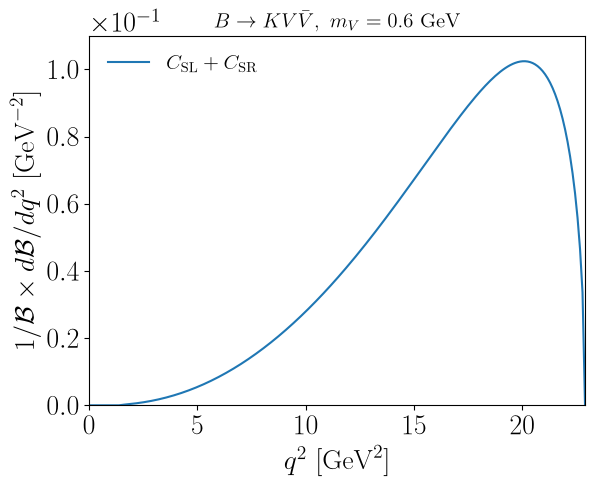

In [6]:
plot_spectra({
    r'$C_{\rm SL} + C_{\rm SR}$': Model("VV", m, CSL = 1., CSR = 1.),
}, K, ylim = (0, 0.11), title = r'$B\to K V\bar{V}, ~ m_V = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoK_3body_vector.pdf")

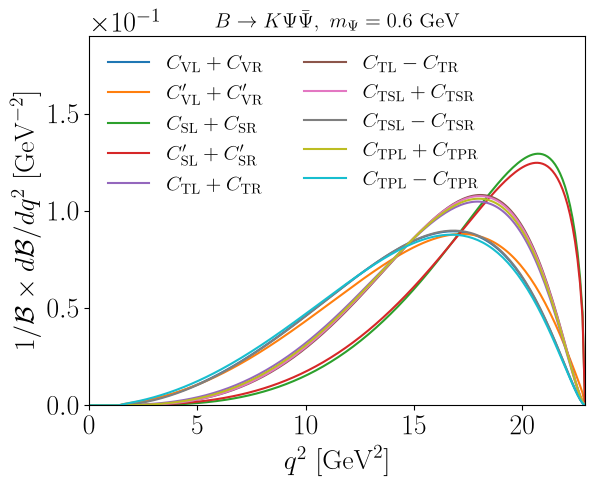

In [7]:
plot_spectra({
    r'$C_{\rm VL} + C_{\rm VR}$': Model("PsiPsi", m, CVL = 1., CVR = 1.),
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$': Model("PsiPsi", m, CVLp = 1., CVRp = 1.),
    r'$C_{\rm SL} + C_{\rm SR}$': Model("PsiPsi", m, CSL = 1., CSR = 1.),
    r'$C_{\rm SL}^{\prime} + C_{\rm SR}^{\prime}$': Model("PsiPsi", m, CSLp = 1., CSRp = 1.),
    r'$C_{\rm TL} + C_{\rm TR}$': Model("PsiPsi", m, CTL = 1., CTR = 1.),
    r'$C_{\rm TL} - C_{\rm TR}$': Model("PsiPsi", m, CTL = 1., CTR = -1.),
    r'$C_{\rm TSL} + C_{\rm TSR}$': Model("PsiPsi", m, CTSL = 1., CTSR = 1.),
    r'$C_{\rm TSL} - C_{\rm TSR}$': Model("PsiPsi", m, CTSL = 1., CTSR = -1.),
    r'$C_{\rm TPL} + C_{\rm TPR}$': Model("PsiPsi", m, CTPL = 1., CTPR = 1.),
    r'$C_{\rm TPL} - C_{\rm TPR}$': Model("PsiPsi", m, CTPL = 1., CTPR = -1.),
}, K, ylim = (0, 0.19), title = r'$B\to K \Psi\bar{\Psi}, ~m_\Psi = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoK_3body_spin32.pdf", ncol = 2)

## $B\to K^{*} E_{\mathrm{miss}}$

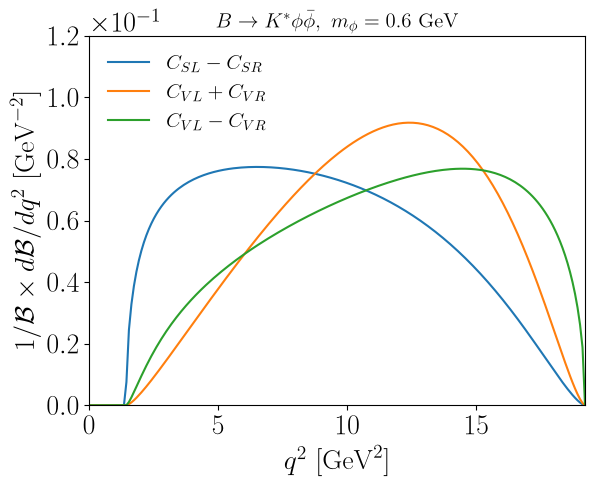

In [8]:
plot_spectra({
    r'$C_{SL} - C_{SR}$': Model("phiphi", m, CSL = 1., CSR = -1.),
    r'$C_{VL} + C_{VR}$': Model("phiphi", m, CVL = 1., CVR = 1.),
    r'$C_{VL} - C_{VR}$': Model("phiphi", m, CVL = 1., CVR = -1.),
}, KS, ylim = (0, 0.12), title = r'$B\to K^* \phi\bar{\phi},~m_\phi = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoKs_3body_scalar.pdf")

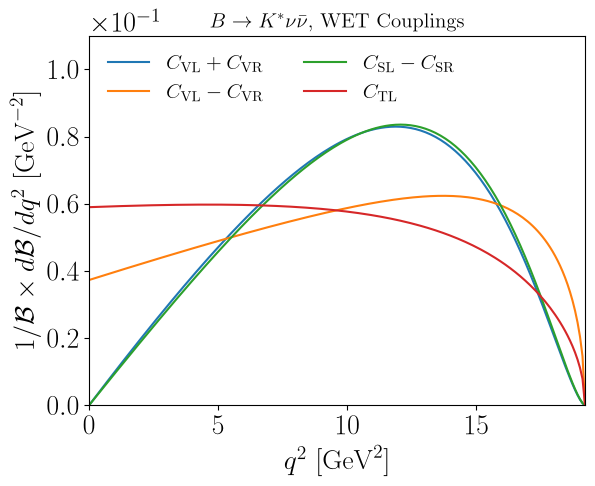

In [9]:
plot_spectra({
    r'$C_{\rm VL} + C_{\rm VR}$': Model("nunu", m, CVL = 1., CVR = 1.),
    r'$C_{\rm VL} - C_{\rm VR}$': Model("nunu", m, CVL = 1., CVR = -1.),
    r'$C_{\rm SL} - C_{\rm SR}$': Model("nunu", m, CSL = 1., CSR = -1.),
    r'$C_{\rm TL}$': Model("nunu", m, CTL = 1.),
}, KS, ylim = (0, 0.11), title = r'$B\to K^* \nu\bar{\nu}$, WET Couplings',
   file = "BtoKs_3body_WET.pdf", ncol = 2)

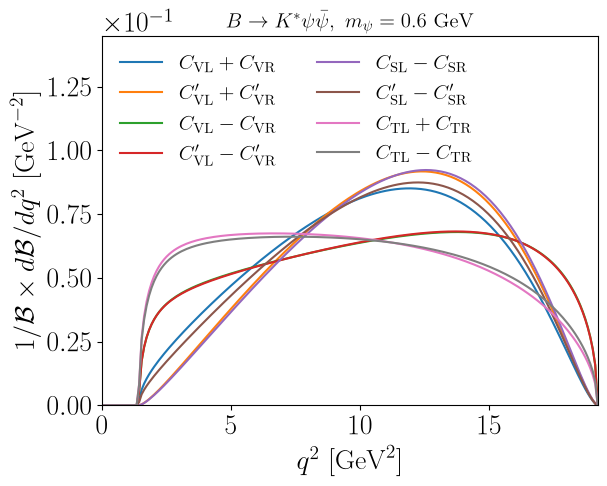

In [10]:
plot_spectra({
    r'$C_{\rm VL} + C_{\rm VR}$': Model("psipsi", m, CVL = 1., CVR = 1.),
    r'$C_{\rm VL}^{\prime} + C_{\rm VR}^{\prime}$': Model("psipsi", m, CVLp = 1., CVRp = 1.),
    r'$C_{\rm VL} - C_{\rm VR}$': Model("psipsi", m, CVL = 1., CVR = -1.),
    r'$C_{\rm VL}^{\prime} - C_{\rm VR}^{\prime}$': Model("psipsi", m, CVLp = 1., CVRp = -1.),
    r'$C_{\rm SL} - C_{\rm SR}$': Model("psipsi", m, CSL = 1., CSR = -1.),
    r'$C_{\rm SL}^{\prime} - C_{\rm SR}^{\prime}$': Model("psipsi", m, CSLp = 1., CSRp = -1.),
    r'$C_{\rm TL} + C_{\rm TR}$': Model("psipsi", m, CTL = 1., CTR = 1.),
    r'$C_{\rm TL} - C_{\rm TR}$': Model("psipsi", m, CTL = 1., CTR = -1.),
}, KS, ylim = (0, 0.145), title = r'$B\to K^* \psi\bar{\psi},~m_\psi = %1.1f~\mathrm{GeV}$' % m,
   file = "BtoKs_3body_fermion.pdf", ncol = 2)